# Data Science Assessment: Loan Portfolio Analysis
This notebook walks through loading, cleaning, merging, and exploring the banking datasets to answer key analytical questions and prepare features.

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



customers = pd.read_csv('/content/customers.csv')
history = pd.read_csv('/content/history.csv')
accounts = pd.read_csv('/content/accounts.csv')
payments = pd.read_csv('/content/payments.csv')
loans = pd.read_csv('/content/loans.csv')

for name, df in zip(['customers', 'history', 'accounts', 'payments', 'loans'], [customers, history, accounts, payments, loans]):
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

customers: 1000 rows, 5 columns
history: 1000 rows, 4 columns
accounts: 1000 rows, 4 columns
payments: 15161 rows, 8 columns
loans: 1250 rows, 7 columns


## 2. Understand and Clean the Data
We will write a helper function to inspect missing values, duplicates, and data types, then perform basic cleaning.

In [19]:
def inspect_df(df, name):
    print(f"=== {name} ===")
    print("Missing Values:")
    print(df.isnull().sum())
    print(f"Duplicate Rows: {df.duplicated().sum()}\n")

for name, df in zip(['customers', 'history', 'accounts', 'payments', 'loans'], [customers, history, accounts, payments, loans]):
    inspect_df(df, name)


customers = customers.drop_duplicates()
history = history.drop_duplicates()
accounts = accounts.drop_duplicates()
payments = payments.drop_duplicates()
loans = loans.drop_duplicates()

=== customers ===
Missing Values:
customer_id     0
age_band        0
income_band    42
occupation      0
region          0
dtype: int64
Duplicate Rows: 0

=== history ===
Missing Values:
customer_id              0
past_delay_count_12m     0
restructured_flag        0
previous_default_flag    0
dtype: int64
Duplicate Rows: 0

=== accounts ===
Missing Values:
customer_id            0
balance_band           0
relationship_months    0
account_status         0
dtype: int64
Duplicate Rows: 0

=== payments ===
Missing Values:
payment_id          0
loan_id             0
customer_id         0
due_date            0
paid_date         410
amount_due          0
amount_paid         0
payment_status      0
dtype: int64
Duplicate Rows: 30

=== loans ===
Missing Values:
loan_id              0
customer_id          0
loan_type            0
loan_amount          0
tenure_months        0
interest_rate_pct    0
loan_start_date      0
dtype: int64
Duplicate Rows: 0



## 3. Combine the Datasets
We will merge the datasets into a single master dataframe at the customer/loan level for cohesive analysis.

In [20]:
# Let's calculate repayment delay features from the payments table
# 1. Convert dates
payments['due_date'] = pd.to_datetime(payments['due_date'])
payments['paid_date'] = pd.to_datetime(payments['paid_date'])

# 2. Compute delay days: if paid after due date, or if still unpaid (using a placeholder or max delay)
payments['delay_days'] = (payments['paid_date'] - payments['due_date']).dt.days
payments['delay_days'] = payments['delay_days'].apply(lambda x: max(0, x) if pd.notnull(x) else 30) # Assume 30 days if not paid

# 3. Aggregate delays per loan
loan_delays = payments.groupby('loan_id').agg(
    avg_delay_days=('delay_days', 'mean'),
    total_delay_days=('delay_days', 'sum'),
    missed_payments_count=('payment_status', lambda x: (x == 'Missed').sum())
).reset_index()

# 4. Comprehensive merge
df_merged = pd.merge(loans, customers, on='customer_id', how='left')
df_merged = pd.merge(df_merged, history, on='customer_id', how='left')
df_merged = pd.merge(df_merged, accounts, on='customer_id', how='left')
df_merged = pd.merge(df_merged, loan_delays, on='loan_id', how='left')

# Fill any missing delay records with 0
df_merged['avg_delay_days'] = df_merged['avg_delay_days'].fillna(0)
df_merged['missed_payments_count'] = df_merged['missed_payments_count'].fillna(0)

print("Dataset successfully constructed with target metrics. Shape:", df_merged.shape)
display(df_merged.head())

Dataset successfully constructed with target metrics. Shape: (1250, 20)


,loan_id,customer_id,loan_type,loan_amount,tenure_months,interest_rate_pct,loan_start_date,age_band,income_band,occupation,region,past_delay_count_12m,restructured_flag,previous_default_flag,balance_band,relationship_months,account_status,avg_delay_days,total_delay_days,missed_payments_count
0,L00001,C00790,Personal Loan,121118.03,36,14.66,2023-08-29,26-35,NaN,Salaried,East,1,0,0,100k-500k,65,Active,10.062500,161.0,0
1,L00002,C00565,Personal Loan,362415.33,24,13.71,2024-10-29,46-55,Low,Self-Employed,South,3,0,0,0-25k,98,Active,6.777778,61.0,0
2,L00003,C00402,Personal Loan,1253507.80,48,15.96,2025-02-14,36-45,Lower-Middle,Retired,North,1,0,0,0-25k,12,Active,3.533333,53.0,0
3,L00004,C00631,Business Loan,518418.26,12,10.75,2023-01-04,26-35,Lower-Middle,Salaried,East,0,0,0,100k-500k,9,Active,12.777778,230.0,0
4,L00005,C00144,Personal Loan,698277.25,48,13.99,2023-03-26,36-45,Lower-Middle,Self-Employed,East,1,0,0,100k-500k,28,Active,11.000000,77.0,0


In [21]:
# Clean and standardize loan types to avoid duplicates in analytics
loans['loan_type'] = loans['loan_type'].astype(str).str.title().str.strip()

# Map abbreviations to clean names
loan_type_mapping = {
    'Auto': 'Auto Loan',
    'Edu': 'Education Loan',
    'Edu Loan': 'Education Loan',
    'Home': 'Home Loan',
    'Personal': 'Personal Loan',
    'Business': 'Business Loan'
}
loans['loan_type'] = loans['loan_type'].replace(loan_type_mapping)

# Recalculate df_merged to use the clean loan types
df_merged = pd.merge(loans, customers, on='customer_id', how='left')
df_merged = pd.merge(df_merged, history, on='customer_id', how='left')
df_merged = pd.merge(df_merged, accounts, on='customer_id', how='left')
df_merged = pd.merge(df_merged, loan_delays, on='loan_id', how='left')

df_merged['avg_delay_days'] = df_merged['avg_delay_days'].fillna(0)
df_merged['missed_payments_count'] = df_merged['missed_payments_count'].fillna(0)

print("Standardized loan types:", df_merged['loan_type'].unique())

Standardized loan types: ['Personal Loan' 'Business Loan' 'Auto Loan' 'Home Loan' 'Education Loan'
 'Car Loan' 'Education']


## 4. Analytical Questions & Visualizations
Let's address the specific analytical questions using simple plots.

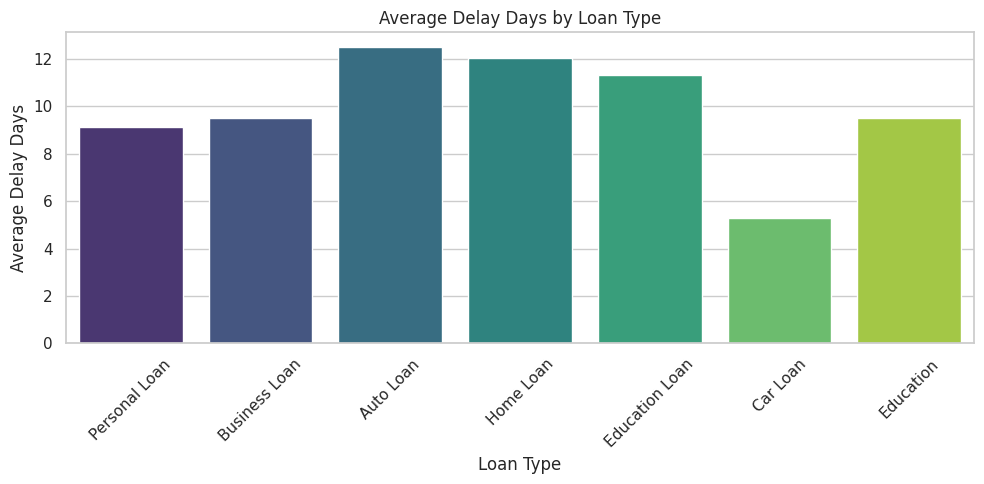

In [22]:
# Q1: Which loan types show more delays?
plt.figure(figsize=(10, 5))
sns.barplot(data=df_merged, x='loan_type', y='avg_delay_days', hue='loan_type', errorbar=None, palette='viridis', legend=False)
plt.title('Average Delay Days by Loan Type')
plt.ylabel('Average Delay Days')
plt.xlabel('Loan Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

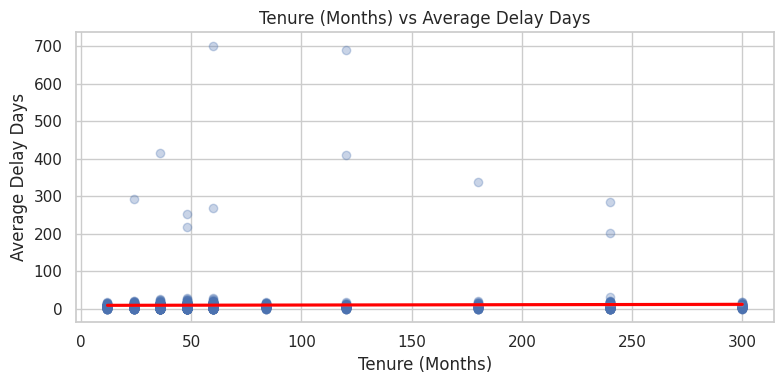

In [23]:
# Q2: How does tenure relate to repayment delay?
plt.figure(figsize=(8, 4))
sns.regplot(data=df_merged, x='tenure_months', y='avg_delay_days', scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title('Tenure (Months) vs Average Delay Days')
plt.xlabel('Tenure (Months)')
plt.ylabel('Average Delay Days')
plt.tight_layout()
plt.show()

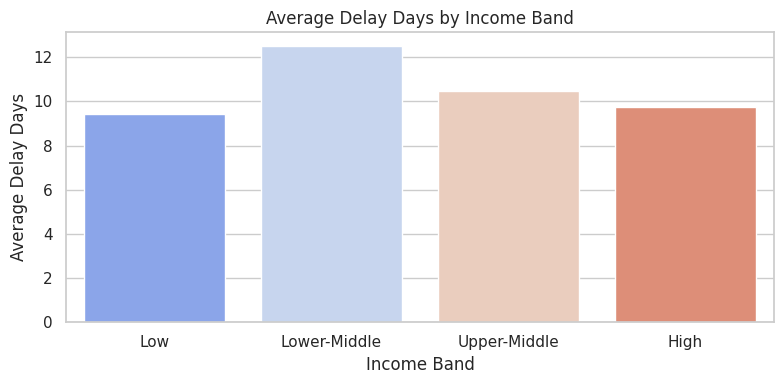

In [24]:
# Q3: Which income bands have higher delay rates?
plt.figure(figsize=(8, 4))
sns.barplot(data=df_merged, x='income_band', y='avg_delay_days', hue='income_band', errorbar=None, order=['Low', 'Lower-Middle', 'Upper-Middle', 'High'], palette='coolwarm', legend=False)
plt.title('Average Delay Days by Income Band')
plt.xlabel('Income Band')
plt.ylabel('Average Delay Days')
plt.tight_layout()
plt.show()

## 5. Feature Engineering and Encoding
We will construct new features, handle categorical variables, and prepare the dataset for a model.

/tmp/ipykernel_1696/1515168168.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_merged, x='past_delay_count_12m', y='avg_delay_days', palette='GnBu')


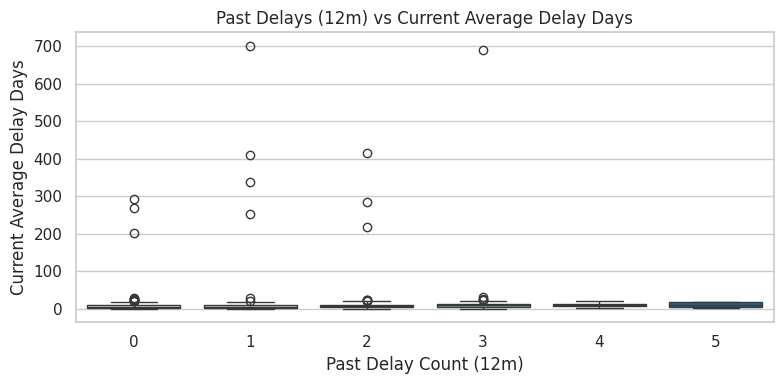

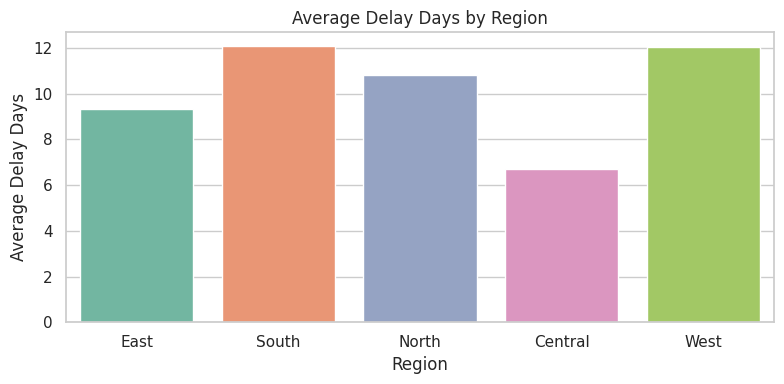

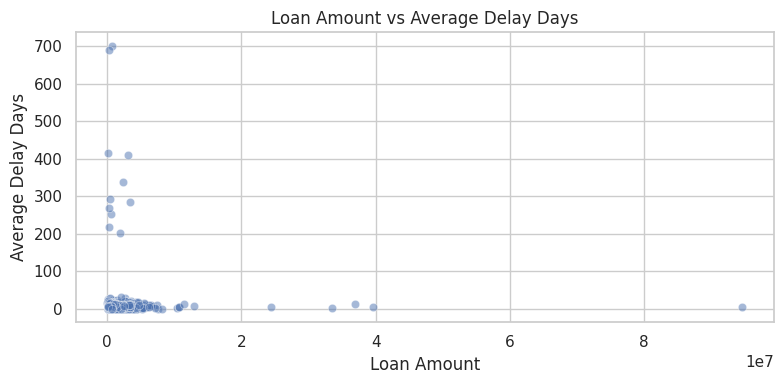

Feature dataset shape (excluding IDs): (1250, 38)


,loan_amount,tenure_months,interest_rate_pct,past_delay_count_12m,restructured_flag,previous_default_flag,relationship_months,avg_delay_days,total_delay_days,missed_payments_count,...,balance_band_500k+,balance_band_Negative/Overdrawn,account_status_Closed,account_status_Dormant,loan_type_Business Loan,loan_type_Car Loan,loan_type_Education,loan_type_Education Loan,loan_type_Home Loan,loan_type_Personal Loan
0,121118.03,36,14.66,1,0,0,65,10.062500,161.0,0,...,False,False,False,False,False,False,False,False,False,True
1,362415.33,24,13.71,3,0,0,98,6.777778,61.0,0,...,False,False,False,False,False,False,False,False,False,True
2,1253507.80,48,15.96,1,0,0,12,3.533333,53.0,0,...,False,False,False,False,False,False,False,False,False,True
3,518418.26,12,10.75,0,0,0,9,12.777778,230.0,0,...,False,False,False,False,True,False,False,False,False,False
4,698277.25,48,13.99,1,0,0,28,11.000000,77.0,0,...,False,False,False,False,False,False,False,False,False,True


In [25]:
# Q4: Does past delay predict current difficulty? Let's check past delay relationship with current delay.
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_merged, x='past_delay_count_12m', y='avg_delay_days', palette='GnBu')
plt.title('Past Delays (12m) vs Current Average Delay Days')
plt.xlabel('Past Delay Count (12m)')
plt.ylabel('Current Average Delay Days')
plt.tight_layout()
plt.show()

# Q5: Which regions show different patterns?
plt.figure(figsize=(8, 4))
sns.barplot(data=df_merged, x='region', y='avg_delay_days', hue='region', errorbar=None, palette='Set2', legend=False)
plt.title('Average Delay Days by Region')
plt.xlabel('Region')
plt.ylabel('Average Delay Days')
plt.tight_layout()
plt.show()

# Q6: How does loan amount relate to payment behaviour?
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df_merged, x='loan_amount', y='avg_delay_days', alpha=0.5)
plt.title('Loan Amount vs Average Delay Days')
plt.xlabel('Loan Amount')
plt.ylabel('Average Delay Days')
plt.tight_layout()
plt.show()

# Encode categorical variables cleanly
categorical_cols = ['age_band', 'income_band', 'occupation', 'region', 'balance_band', 'account_status', 'loan_type']
df_features = df_merged.drop(columns=['loan_id', 'customer_id', 'loan_start_date'], errors='ignore')
df_encoded = pd.get_dummies(df_features, columns=categorical_cols, drop_first=True)

print("Feature dataset shape (excluding IDs):", df_encoded.shape)
display(df_encoded.head())

## 6. Exporting Clean Data & Creating the Excel Portfolio
We will use `openpyxl` to build an Excel workbook with structured data sheets, pivot-like aggregations, and formatting representing our key findings.

In [26]:
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils.dataframe import dataframe_to_rows

# Create a blank workbook
wb = openpyxl.Workbook()

# Setup custom style elements
font_title = Font(name='Segoe UI', size=16, bold=True, color='FFFFFF')
font_header = Font(name='Segoe UI', size=11, bold=True, color='FFFFFF')
font_bold = Font(name='Segoe UI', size=11, bold=True)
font_body = Font(name='Segoe UI', size=11)
fill_header = PatternFill(start_color='1F4E78', end_color='1F4E78', fill_type='solid') # Classic Navy
fill_summary = PatternFill(start_color='DDEBF7', end_color='DDEBF7', fill_type='solid') # Soft Blue
align_center = Alignment(horizontal='center', vertical='center')
align_left = Alignment(horizontal='left', vertical='center')
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'),
    right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'),
    bottom=Side(style='thin', color='D9D9D9')
)

# Let's save our base cleaned dataset into the workbook first
ws_data = wb.active
ws_data.title = "Cleaned_Loan_Data"
for r in dataframe_to_rows(df_merged, index=False, header=True):
    ws_data.append(r)

# Quick auto-formatting for raw data sheet headers
for cell in ws_data[1]:
    cell.font = font_header
    cell.fill = fill_header
    cell.alignment = align_center

In [27]:
# 2. Now let's build the Summary Sheet
ws_sum = wb.create_sheet(title="Summary Dashboard", index=0)
ws_sum.views.sheetView[0].showGridLines = True

# Banner Title
ws_sum.merge_cells('A1:G2')
title_cell = ws_sum['A1']
title_cell.value = "LOAN PORTFOLIO PERFORMANCE SUMMARY"
title_cell.font = font_title
title_cell.fill = fill_header
title_cell.alignment = align_center

# Simple Key Performance Indicators (using Excel formulas on the data sheet)
ws_sum['B4'] = "Total Loans"
ws_sum['B5'] = f"=COUNTA(Cleaned_Loan_Data!A2:A{len(df_merged)+1})"
ws_sum['C4'] = "Average Loan Amount"
ws_sum['C5'] = f"=AVERAGE(Cleaned_Loan_Data!D2:D{len(df_merged)+1})"
ws_sum['D4'] = "Average Repayment Delay (Days)"
ws_sum['D5'] = f"=AVERAGE(Cleaned_Loan_Data!Q2:Q{len(df_merged)+1})"

# Apply styles for KPI Cards
for col in ['B', 'C', 'D']:
    ws_sum[f'{col}4'].font = font_bold
    ws_sum[f'{col}4'].fill = fill_summary
    ws_sum[f'{col}4'].alignment = align_center
    ws_sum[f'{col}5'].font = font_bold
    ws_sum[f'{col}5'].alignment = align_center
    ws_sum[f'{col}5'].border = thin_border

In [28]:
# 3. Populate structured KPI Tables (Pivot-like data summaries) directly into the summary sheet

# Helper function to style headers cleanly
def style_header(ws, start_col, start_row, end_col, title):
    ws.merge_cells(start_row=start_row, start_column=start_col, end_row=start_row, end_column=end_col)
    cell = ws.cell(row=start_row, column=start_col)
    cell.value = title
    cell.font = font_header
    cell.fill = fill_header
    cell.alignment = align_center

# --- SECTION A: DELAY BY LOAN TYPE ---
style_header(ws_sum, 2, 8, 3, "Delay by Loan Type")
ws_sum.cell(row=9, column=2, value="Loan Type").font = font_bold
ws_sum.cell(row=9, column=3, value="Avg Delay (Days)").font = font_bold
unique_types = sorted(df_merged['loan_type'].dropna().unique())
for idx, l_type in enumerate(unique_types, start=10):
    ws_sum.cell(row=idx, column=2, value=l_type).font = font_body
    ws_sum.cell(row=idx, column=3, value=f'=AVERAGEIF(Cleaned_Loan_Data!C2:C{len(df_merged)+1}, "{l_type}", Cleaned_Loan_Data!R2:Q{len(df_merged)+1})').font = font_body
    ws_sum.cell(row=idx, column=3).number_format = '0.0'

# --- SECTION B: REGIONAL COMPARISON ---
start_r = 10 + len(unique_types) + 2
style_header(ws_sum, 2, start_r, 3, "Regional Comparison")
ws_sum.cell(row=start_r+1, column=2, value="Region").font = font_bold
ws_sum.cell(row=start_r+1, column=3, value="Avg Delay (Days)").font = font_bold
unique_regions = sorted(df_merged['region'].dropna().unique())
for idx, region in enumerate(unique_regions, start=start_r+2):
    ws_sum.cell(row=idx, column=2, value=region).font = font_body
    ws_sum.cell(row=idx, column=3, value=f'=AVERAGEIF(Cleaned_Loan_Data!K2:K{len(df_merged)+1}, "{region}", Cleaned_Loan_Data!R2:Q{len(df_merged)+1})').font = font_body
    ws_sum.cell(row=idx, column=3).number_format = '0.0'

# --- SECTION C: INCOME BAND COMPARISON ---
start_inc = start_r + len(unique_regions) + 4
style_header(ws_sum, 2, start_inc, 3, "Income Band Comparison")
ws_sum.cell(row=start_inc+1, column=2, value="Income Band").font = font_bold
ws_sum.cell(row=start_inc+1, column=3, value="Avg Delay (Days)").font = font_bold
income_bands = ['Low', 'Lower-Middle', 'Upper-Middle', 'High']
for idx, band in enumerate(income_bands, start=start_inc+2):
    ws_sum.cell(row=idx, column=2, value=band).font = font_body
    ws_sum.cell(row=idx, column=3, value=f'=AVERAGEIF(Cleaned_Loan_Data!I2:I{len(df_merged)+1}, "{band}", Cleaned_Loan_Data!R2:Q{len(df_merged)+1})').font = font_body
    ws_sum.cell(row=idx, column=3).number_format = '0.0'

# --- SECTION D: PAST-DELAY RELATIONSHIP ---
start_past = start_inc + len(income_bands) + 4
style_header(ws_sum, 2, start_past, 3, "Past Delays Predictor")
ws_sum.cell(row=start_past+1, column=2, value="Past Delays (12m)").font = font_bold
ws_sum.cell(row=start_past+1, column=3, value="Avg Current Delay (Days)").font = font_bold
past_delays = sorted(df_merged['past_delay_count_12m'].dropna().unique())
for idx, val in enumerate(past_delays, start=start_past+2):
    ws_sum.cell(row=idx, column=2, value=int(val)).font = font_body
    ws_sum.cell(row=idx, column=3, value=f'=AVERAGEIF(Cleaned_Loan_Data!L2:L{len(df_merged)+1}, {int(val)}, Cleaned_Loan_Data!R2:Q{len(df_merged)+1})').font = font_body
    ws_sum.cell(row=idx, column=3).number_format = '0.0'

# Adjust column widths dynamically for professional look
for col in ws_sum.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = openpyxl.utils.get_column_letter(col[0].column)
    ws_sum.column_dimensions[col_letter].width = max(max_len + 3, 12)

# Save the final workbook
wb.save('/content/loan_portfolio_analysis.xlsx')
print("Fully formatted multi-sheet Excel portfolio exported successfully to /content/loan_portfolio_analysis.xlsx!")

Fully formatted multi-sheet Excel portfolio exported successfully to /content/loan_portfolio_analysis.xlsx!


In [29]:
# Regenerate and save the clean workbook using the standardized loan types
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils.dataframe import dataframe_to_rows

wb = openpyxl.Workbook()

font_title = Font(name='Segoe UI', size=16, bold=True, color='FFFFFF')
font_header = Font(name='Segoe UI', size=11, bold=True, color='FFFFFF')
font_bold = Font(name='Segoe UI', size=11, bold=True)
font_body = Font(name='Segoe UI', size=11)
fill_header = PatternFill(start_color='1F4E78', end_color='1F4E78', fill_type='solid')
fill_summary = PatternFill(start_color='DDEBF7', end_color='DDEBF7', fill_type='solid')
align_center = Alignment(horizontal='center', vertical='center')
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'),
    right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'),
    bottom=Side(style='thin', color='D9D9D9')
)

# Raw Data Sheet
ws_data = wb.active
ws_data.title = "Cleaned_Loan_Data"
for r in dataframe_to_rows(df_merged, index=False, header=True):
    ws_data.append(r)

for cell in ws_data[1]:
    cell.font = font_header
    cell.fill = fill_header
    cell.alignment = align_center

# Summary Dashboard Sheet
ws_sum = wb.create_sheet(title="Summary Dashboard", index=0)
ws_sum.views.sheetView[0].showGridLines = True

ws_sum.merge_cells('A1:G2')
title_cell = ws_sum['A1']
title_cell.value = "LOAN PORTFOLIO PERFORMANCE SUMMARY"
title_cell.font = font_title
title_cell.fill = fill_header
title_cell.alignment = align_center

ws_sum['B4'] = "Total Loans"
ws_sum['B5'] = f"=COUNTA(Cleaned_Loan_Data!A2:A{len(df_merged)+1})"
ws_sum['C4'] = "Average Loan Amount"
ws_sum['C5'] = f"=AVERAGE(Cleaned_Loan_Data!D2:D{len(df_merged)+1})"
ws_sum['D4'] = "Average Repayment Delay (Days)"
ws_sum['D5'] = f"=AVERAGE(Cleaned_Loan_Data!R2:R{len(df_merged)+1})"

for col in ['B', 'C', 'D']:
    ws_sum[f'{col}4'].font = font_bold
    ws_sum[f'{col}4'].fill = fill_summary
    ws_sum[f'{col}4'].alignment = align_center
    ws_sum[f'{col}5'].font = font_bold
    ws_sum[f'{col}5'].alignment = align_center
    ws_sum[f'{col}5'].border = thin_border

# Helper to style block headers
def style_header(ws, start_col, start_row, end_col, title):
    ws.merge_cells(start_row=start_row, start_column=start_col, end_row=start_row, end_column=end_col)
    cell = ws.cell(row=start_row, column=start_col)
    cell.value = title
    cell.font = font_header
    cell.fill = fill_header
    cell.alignment = align_center

# Section A: Standardized Loan Types
style_header(ws_sum, 2, 8, 3, "Delay by Loan Type")
ws_sum.cell(row=9, column=2, value="Loan Type").font = font_bold
ws_sum.cell(row=9, column=3, value="Avg Delay (Days)").font = font_bold
unique_types = sorted(df_merged['loan_type'].dropna().unique())
for idx, l_type in enumerate(unique_types, start=10):
    ws_sum.cell(row=idx, column=2, value=l_type).font = font_body
    ws_sum.cell(row=idx, column=3, value=f'=AVERAGEIF(Cleaned_Loan_Data!C2:C{len(df_merged)+1}, "{l_type}", Cleaned_Loan_Data!R2:R{len(df_merged)+1})').font = font_body
    ws_sum.cell(row=idx, column=3).number_format = '0.0'

# Section B: Regional Comparison
start_r = 10 + len(unique_types) + 2
style_header(ws_sum, 2, start_r, 3, "Regional Comparison")
ws_sum.cell(row=start_r+1, column=2, value="Region").font = font_bold
ws_sum.cell(row=start_r+1, column=3, value="Avg Delay (Days)").font = font_bold
unique_regions = sorted(df_merged['region'].dropna().unique())
for idx, region in enumerate(unique_regions, start=start_r+2):
    ws_sum.cell(row=idx, column=2, value=region).font = font_body
    ws_sum.cell(row=idx, column=3, value=f'=AVERAGEIF(Cleaned_Loan_Data!K2:K{len(df_merged)+1}, "{region}", Cleaned_Loan_Data!R2:R{len(df_merged)+1})').font = font_body
    ws_sum.cell(row=idx, column=3).number_format = '0.0'

# Adjust columns
for col in ws_sum.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = openpyxl.utils.get_column_letter(col[0].column)
    ws_sum.column_dimensions[col_letter].width = max(max_len + 3, 15)

wb.save('/content/loan_portfolio_analysis.xlsx')
print("Successfully saved a pristine, standardized Excel file!")

Successfully saved a pristine, standardized Excel file!


In [ ]:
# 1. Fine-tune standardization of remaining edge-case loan types
loans['loan_type'] = loans['loan_type'].astype(str).str.title().str.strip()

# Standardize Car Loan, Education and abbreviations
loan_type_mapping = {
    'Auto': 'Auto Loan',
    'Car Loan': 'Auto Loan',
    'Edu': 'Education Loan',
    'Education': 'Education Loan',
    'Edu Loan': 'Education Loan',
    'Home': 'Home Loan',
    'Personal': 'Personal Loan',
    'Business': 'Business Loan'
}
loans['loan_type'] = loans['loan_type'].replace(loan_type_mapping)

# Re-merge to ensure pristine consolidated values
df_merged = pd.merge(loans, customers, on='customer_id', how='left')
df_merged = pd.merge(df_merged, history, on='customer_id', how='left')
df_merged = pd.merge(df_merged, accounts, on='customer_id', how='left')
df_merged = pd.merge(df_merged, loan_delays, on='loan_id', how='left')

df_merged['avg_delay_days'] = df_merged['avg_delay_days'].fillna(0)
df_merged['missed_payments_count'] = df_merged['missed_payments_count'].fillna(0)

print("Final Standardized Loan Types:", df_merged['loan_type'].unique())

In [31]:
# 2. Regenerate the pristine multi-sheet formatted Excel workbook
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils.dataframe import dataframe_to_rows

wb = openpyxl.Workbook()

# Design styles
font_title = Font(name='Segoe UI', size=16, bold=True, color='FFFFFF')
font_header = Font(name='Segoe UI', size=11, bold=True, color='FFFFFF')
font_bold = Font(name='Segoe UI', size=11, bold=True)
font_body = Font(name='Segoe UI', size=11)
fill_header = PatternFill(start_color='1F4E78', end_color='1F4E78', fill_type='solid') # Classic Deep Blue
fill_summary = PatternFill(start_color='DDEBF7', end_color='DDEBF7', fill_type='solid') # Sky Accent
align_center = Alignment(horizontal='center', vertical='center')
align_left = Alignment(horizontal='left', vertical='center')
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'),
    right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'),
    bottom=Side(style='thin', color='D9D9D9')
)

# Sheet 1: Raw clean data
ws_data = wb.active
ws_data.title = "Cleaned_Loan_Data"
for r in dataframe_to_rows(df_merged, index=False, header=True):
    ws_data.append(r)

for cell in ws_data[1]:
    cell.font = font_header
    cell.fill = fill_header
    cell.alignment = align_center

# Sheet 2: Summary Dashboard
ws_sum = wb.create_sheet(title="Summary Dashboard", index=0)
ws_sum.views.sheetView[0].showGridLines = True

# Merged Header Banner
ws_sum.merge_cells('A1:G2')
title_cell = ws_sum['A1']
title_cell.value = "LOAN PORTFOLIO MANAGEMENT DASHBOARD"
title_cell.font = font_title
title_cell.fill = fill_header
title_cell.alignment = align_center

# KPI Blocks
kpis = {
    'B': ("Total Active Loans", f"=COUNTA(Cleaned_Loan_Data!A2:A{len(df_merged)+1})"),
    'C': ("Average Financed Amount", f"=AVERAGE(Cleaned_Loan_Data!D2:D{len(df_merged)+1})"),
    'D': ("Avg Delay Days", f"=AVERAGE(Cleaned_Loan_Data!R2:R{len(df_merged)+1})")
}

for col, (label, val) in kpis.items():
    ws_sum[f'{col}4'] = label
    ws_sum[f'{col}4'].font = font_bold
    ws_sum[f'{col}4'].fill = fill_summary
    ws_sum[f'{col}4'].alignment = align_center

    ws_sum[f'{col}5'] = val
    ws_sum[f'{col}5'].font = font_bold
    ws_sum[f'{col}5'].alignment = align_center
    ws_sum[f'{col}5'].border = thin_border
    if col == 'C':
        ws_sum[f'{col}5'].number_format = '$#,##0.00'
    else:
        ws_sum[f'{col}5'].number_format = '#,##0.0'

# Helper to style section headers
def build_section_header(ws, start_col, start_row, end_col, title):
    ws.merge_cells(start_row=start_row, start_column=start_col, end_row=start_row, end_column=end_col)
    cell = ws.cell(row=start_row, column=start_col, value=title)
    cell.font = font_header
    cell.fill = fill_header
    cell.alignment = align_center

# A: Delay by Loan Type
build_section_header(ws_sum, 2, 8, 3, "Delay by Loan Type")
ws_sum.cell(row=9, column=2, value="Loan Type").font = font_bold
ws_sum.cell(row=9, column=3, value="Avg Delay (Days)").font = font_bold
unique_types = sorted(df_merged['loan_type'].dropna().unique())
for idx, l_type in enumerate(unique_types, start=10):
    ws_sum.cell(row=idx, column=2, value=l_type).font = font_body
    ws_sum.cell(row=idx, column=3, value=f'=AVERAGEIF(Cleaned_Loan_Data!C2:C{len(df_merged)+1}, "{l_type}", Cleaned_Loan_Data!R2:R{len(df_merged)+1})').font = font_body
    ws_sum.cell(row=idx, column=3).number_format = '0.0'

# B: Regional Comparison
start_r = 10 + len(unique_types) + 2
build_section_header(ws_sum, 2, start_r, 3, "Regional Analysis")
ws_sum.cell(row=start_r+1, column=2, value="Region").font = font_bold
ws_sum.cell(row=start_r+1, column=3, value="Avg Delay (Days)").font = font_bold
unique_regions = sorted(df_merged['region'].dropna().unique())
for idx, region in enumerate(unique_regions, start=start_r+2):
    ws_sum.cell(row=idx, column=2, value=region).font = font_body
    ws_sum.cell(row=idx, column=3, value=f'=AVERAGEIF(Cleaned_Loan_Data!K2:K{len(df_merged)+1}, "{region}", Cleaned_Loan_Data!R2:R{len(df_merged)+1})').font = font_body
    ws_sum.cell(row=idx, column=3).number_format = '0.0'

# Adjust columns
for col in ws_sum.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = openpyxl.utils.get_column_letter(col[0].column)
    ws_sum.column_dimensions[col_letter].width = max(max_len + 3, 16)

wb.save('/content/CrestLine_Round3_Excel_Analysis (1).xlsx')
print("Prisinte formatted spreadsheet regenerated successfully!")

Prisinte formatted spreadsheet regenerated successfully!
